# Textual Entailment Fact Checking

Use a pre-trained DeBERTa-v3 NLI model (MNLI + FEVER + ANLI) to decide whether each fact (hypothesis) is entailed by a passage sentence (premise). The three-way output (entailment / neutral / contradiction) is mapped to S / NS. Target should be more than or equal to 83% accuracy.

**Plan is to** run the model once over every (sentence, fact) pair -> cache the probabilities -> tune decision rules, thresholds and pruning offline.

## 1. Imports and paths

In [ ]:
# searching modules
import sys
# Finds and splits text using patterns
import re
import json
import time
# Helps clean up unused objects and free memory
import gc
from pathlib import Path

import numpy as np
# Runs the deep learning model
import torch
# AutoTokenizer converts text into tokens the model can understand
# AutoModelForSequenceClassification is a model class for sequence classification tasks
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Project root (two levels up) so we can import factcheck.py and factchecking_main.py directly.
ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT))

# Reuse the official loaders
# read_passages: loads evidence passages
# read_fact_examples: loads the facts and their labels, along with the associated evidence
from factchecking_main import read_passages, read_fact_examples
# Reuse the Part 1 word-overlap scorer for pruning
from factcheck import WordRecallThresholdFactChecker

/Users/seyedrumaiz/Library/Mobile Documents/com~apple~CloudDocs/University/Year 3/CM3604/LLMFactChecking/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Seed for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Save the model's predictions there so it doesn't need to repeat expensive calculations
CACHE_DIR = Path("cache")
CACHE_DIR.mkdir(exist_ok=True)

## 2. Load data (loaders of factchecking_main.py)

In [3]:
# Load the data and convert to binary labels (S vs NS, where NS includes IR)
fact_to_passage = read_passages(str(ROOT / "data/passages_bm25_ChatGPT_humfacts.jsonl"))    # Loads the evidence passages
examples = read_fact_examples(str(ROOT / "data/dev_labeled_ChatGPT.jsonl"), fact_to_passage)    # Loads the labelled facts

# IR -> NS, exactly like predict_two_classes() in factchecking_main.py
# Due to binary classification, we treat "S" as 1 and everything else ("NS" and "IR") as 0
y_true = np.array([1 if ex.label == "S" else 0 for ex in examples])

print(f"Examples: {len(examples)}  |  S = {y_true.sum()}  |  NS (incl. IR) = {(y_true == 0).sum()}")

Examples: 221  |  S = 112  |  NS (incl. IR) = 109


## 3. Load the entailment model

In [4]:
MODEL_NAME = "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli"

# Downloads or loads the tokenizer associated with the model. Converts text into numerical tokens.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
# Loads the pre-trained neural network and its classification head
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
# Put model in evaluation mode, so no training
model.eval()

# Displays the mapping between output numbers and their labels.
# premise = evidence from wikipedia, hypothesis = the fact from chatgpt
print(model.config.id2label)

{0: 'entailment', 1: 'neutral', 2: 'contradiction'}


## 4. Smoke test on one pair

In [5]:
def entailment_probs(premises, hypotheses, batch_size=16):
    """
    Args:
        premises: the evidence texts.
        hypotheses: the facts to check.
        batch_size=16: process upto 16 pairs at a time.

    It takes evidence sentences and facts, runs them through the model,
    and returns three probabilities for each pair: entailment, neutral, and contradiction.
    """

    # Store the results from each batch in a list, then combine them at the end.
    all_probs = []

    # During training, neural networks calculate gradients to update their weights
    # Here, the model is only making predictions, so gradients are unnecessary
    # disable gradient calculations for inference, which saves memory and speeds up computations
    with torch.no_grad():

        # Process each batch of premises and hypotheses
        for start in range(0, len(premises), batch_size):

            # Converts the text pairs into model inputs.
            inputs = tokenizer(
                premises[start:start + batch_size], # select the evidence sentences for this batch
                hypotheses[start:start + batch_size],   # selects the corresponding facts
                padding=True,   # makes sequences in the batch the same length by adding padding tokens
                truncation=True,    # cuts sequences that exceed the tokenizer's max length
                return_tensors="pt",    # returns pytorch tensors
            )

            # get predictions
            logits = model(**inputs).logits
            # softmax converts the raw scores into probabilities that sum to 1 across the three classes 
            # (entailment, neutral, contradiction)
            all_probs.append(torch.softmax(logits, dim=-1).numpy())

            # remove inferences to temporary objects
            del inputs, logits
    gc.collect()

    # np.vstack() combines the batch results into one NumPy array
    # If there are 100 pairs, the output has shape (100, 3).
    return np.vstack(all_probs)

In [6]:
# Smoke test so model and function work
tests = [
    ("Lanny Flaherty (born July 27, 1942) is an American actor.", "Lanny Flaherty is an American."),       # entail
    ("Lanny Flaherty (born July 27, 1942) is an American actor.", "Lanny Flaherty was born in 1950."),     # contradict
    ("Lanny Flaherty (born July 27, 1942) is an American actor.", "Lanny Flaherty plays the guitar."),     # be neutral
]

In [7]:
# The two list comprehensions extract the premises and hypotheses from the pairs.
probs = entailment_probs([p for p, _ in tests], [h for _, h in tests])

# check whether the outputs look reasonable before running the model over the full dataset
for (p, h), pr in zip(tests, probs):
    print(f"E={pr[0]:.3f}  N={pr[1]:.3f}  C={pr[2]:.3f}  |  {h}")

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


E=0.998  N=0.002  C=0.000  |  Lanny Flaherty is an American.
E=0.000  N=0.000  C=0.999  |  Lanny Flaherty was born in 1950.
E=0.000  N=0.997  C=0.003  |  Lanny Flaherty plays the guitar.


## 5. Sentence splitting and cleaning

In [8]:
def split_passage(text):
    """
    This function takes a passage of text and splits it into
    individual sentences, while filtering out any that are too short to be meaningful.
    """

    sentences = [] # Creates an empty list to collect the sentences

    # Splits the passage wherever it encounters the special tags <s> or </s>
    # </?> means that slash is optional
    for chunk in re.split(r"</?s>", text):
        chunk = chunk.strip()
        if not chunk:
            continue

        # Splits a chunk at whitespace that follows a full stop, question mark or exclamation mark.
        for sent in re.split(r"(?<=[.!?])\s+", chunk):
            # Replaces repeated whitespace with a single space and trims the sentence.
            sent = re.sub(r"\s+", " ", sent).strip()

            # keeps sentences with atleast 3 words
            if len(sent.split()) >= 3:
                sentences.append(sent)
    return sentences

In [9]:
ex = examples[0]
print("FACT:", ex.fact)

FACT: Marianne McAndrew is an American.


In [10]:
for s in split_passage(ex.passages[0]["text"])[:5]:
    print("  -", s)

  - Marianne McAndrew Marianne Christine McAndrew is an actress known for her role as Irene Molloy in the film "Hello, Dolly!"
  - "Hello, Dolly!" was McAndrew's first credited film role.
  - The role of Irene Molloy was given considerably more attention in the film than in earlier Broadway productions.
  - "Hello, Dolly!" earned McAndrew two Golden Globe nominations in 1969; Golden Globe Award for Best Supporting Actress – Motion Picture and the since discontinued Golden Globe Award for New Star of the Year – Actress, as well as generally good reviews.
  - She landed a starring (second billed) role in her next film ("The Seven Minutes").


## 6. Run the model once on every pair and cache the results

In [11]:
# Part 1 IDF-recall, reused for pruning later
overlap_scorer = WordRecallThresholdFactChecker(
    passages_path=str(ROOT / "data/passages_bm25_ChatGPT_humfacts.jsonl"))

In [12]:
# Stores information about each evidence-sentence/fact pair.
rows = []

In [13]:
# Go through every fact example.
for i, ex in enumerate(examples):
    # Go through every evidence passage associated with that fact.
    for p_idx, passage in enumerate(ex.passages):
        sents = split_passage(passage["text"])
        # Split each passage into sentences.
        for s_idx, sent in enumerate(sents):
            # for each sentence, store the fact index, passage index, sentence index, the sentence itself,
            # a 2-sentence window (previous + current)
            rows.append({
                "fact_idx": i,  # Which fact this sentence is checking
                "passage_idx": p_idx,   # Which passage contains the sentence
                "sent_idx": s_idx,      # The sentence's position in the passage
                "premise": sent,        # the current sentence alone
                # 2-sentence window (previous + current) to help with pronouns like "He was born..."
                "premise_window": (sents[s_idx - 1] + " " + sent) if s_idx > 0 else sent,
                # the part 1 word-overlap score between the fact and the current sentence
                "overlap": overlap_scorer.score(ex.fact, [{"text": sent}]),
            })

Consider these two sentences:
Lanny Flaherty is an American actor. He was born in 1942.

The fact might be:
Lanny Flaherty was born in 1942.

The second sentence uses He instead of the person's name. If the model sees only the second sentence, it has less context to identify who He refers to.

Combining the previous and current sentences gives the model more context.

For the first sentence, there is no previous sentence, so the code uses the current sentence alone.

In [14]:
print(f"Total pairs: {len(rows)}")

Total pairs: 5417


In [15]:
# prepare inputs for the model
# for every stored row, retrieve the fact associated with it
hypotheses = [examples[r["fact_idx"]].fact for r in rows]

In [16]:
start = time.time()
# Run the model on each individual sentence and its corresponding fact
probs_sent = entailment_probs([r["premise"] for r in rows], hypotheses)

print(f"Sentence premises done in {time.time() - start:.0f}s")

Sentence premises done in 243s


In [17]:
start = time.time()
# Runs the model again on each previous-plus-current sentence window and its corresponding fact
probs_window = entailment_probs([r["premise_window"] for r in rows], hypotheses)
print(f"Window premises done in {time.time() - start:.0f}s")

Window premises done in 377s


In [18]:
# Save everything so later experiments never need to re-run the model.
# Which fact each pair belongs to.
# The word-overlap scores.
# The sentence-based model probabilities.
# The window-based model probabilities.
# The correct labels.
np.savez(
    CACHE_DIR / "pair_probs.npz",
    fact_idx=np.array([r["fact_idx"] for r in rows]),
    overlap=np.array([r["overlap"] for r in rows]),
    probs_sent=probs_sent,
    probs_window=probs_window,
    y_true=y_true,
)
with open(CACHE_DIR / "pairs.jsonl", "w", encoding="utf-8") as f:
    for r in rows:
        f.write(json.dumps(r) + "\n")
print("Cached to", CACHE_DIR)

Cached to cache


Why caching? -> Since we can test many thresholds and decision rules without repeatedly running the transformer model. That saves time and computational resources.

## 7. Load cached results and helpers

In [19]:
# Load the cached model outputs
cache = np.load(CACHE_DIR / "pair_probs.npz")
fact_idx = cache["fact_idx"]       # which fact each pair belongs to
pair_overlap = cache["overlap"]      # per-sentence word overlap (Part 1 scorer)
probs_sent = cache["probs_sent"]      # [P(E), P(N), P(C)] with single-sentence premise
probs_window = cache["probs_window"]  # same, with previous + current sentence as premise
N_FACTS = len(y_true)

In [20]:
def max_per_fact(values, mask=None, default=0.0):
    """Fact score = max over its (kept) sentence pairs."""

    # If no mask is supplied, every pair is included. 
    # Otherwise, only the pairs selected by the Boolean mask are used.
    keep = np.ones(len(values), dtype=bool) if mask is None else mask

    # creates an array with one initial score per fact.
    scores = np.full(N_FACTS, default, dtype=float)

    # for each retained pair, update its fact's score if the pair's value
    # is higher than the score currently stored.
    # np.maximum.at() is useful because many pairs can belong to the same fact.
    # If a fact has no retained pairs, its score stays at default.
    np.maximum.at(scores, fact_idx[keep], values[keep])
    return scores

In [21]:
def accuracy(pred):
    """
    Compares predicted labels with the correct labels.
    """
    return float((pred == y_true).mean())

In [22]:
def tune_threshold(scores, lo=0.0, hi=1.0, steps=1001):
    """
    This tests different thresholds to find the one giving the highest accuracy.
    """

    # t is the threshold
    # generate evenly spaced thresholds between lo and hi, inclusive
    grid = np.linspace(lo, hi, steps)
    accs = np.array([accuracy((scores >= t).astype(int)) for t in grid])
    best = int(np.argmax(accs))
    return float(grid[best]), float(accs[best])

In [23]:
def confusion(pred):
    """
    Calculates the confusion matrix.
    """
    return {
        "TP": int(((pred == 1) & (y_true == 1)).sum()), # A supported fact correctly predicted as supported
        "FN": int(((pred == 0) & (y_true == 1)).sum()), # A non-supported fact correctly predicted as non-supported
        "FP": int(((pred == 1) & (y_true == 0)).sum()), # A non-supported fact incorrectly predicted as supported
        "TN": int(((pred == 0) & (y_true == 0)).sum()), # A supported fact incorrectly predicted as non-supported
    }

## 8. Decision strategies: 3-way NLI output -> S / NS

In [24]:
# Compare strategies for mapping 3-way NLI output -> binary S / NS.
strategy_rows = []

In [25]:
for premise_name, P in [("sentence", probs_sent), ("prev + current sentence", probs_window)]:
    # Discrete: S if ANY sentence's argmax label is "entailment".
    is_entailed = (P.argmax(axis=1) == 0).astype(float)
    pred = (max_per_fact(is_entailed) > 0).astype(int)
    strategy_rows.append((premise_name, "Discrete (argmax = entailment)", None, accuracy(pred)))

    # Threshold on max P(entailment).
    t, acc = tune_threshold(max_per_fact(P[:, 0]))
    strategy_rows.append((premise_name, "Threshold on max P(E)", t, acc))

    # Threshold on max [P(E) - P(C)] (penalises contradicting evidence).
    t, acc = tune_threshold(max_per_fact(P[:, 0] - P[:, 2], default=-1.0), lo=-1.0, hi=1.0, steps=2001)
    strategy_rows.append((premise_name, "Threshold on max [P(E) - P(C)]", t, acc))

In [26]:
print(f"{'Premise':<26}{'Decision rule':<34}{'theta':>8}{'Accuracy':>10}")
for premise_name, rule, t, acc in strategy_rows:
    t_str = f"{t:.3f}" if t is not None else "-"
    print(f"{premise_name:<26}{rule:<34}{t_str:>8}{acc:>10.4f}")

Premise                   Decision rule                        theta  Accuracy
sentence                  Discrete (argmax = entailment)           -    0.8100
sentence                  Threshold on max P(E)                0.322    0.8190
sentence                  Threshold on max [P(E) - P(C)]       0.086    0.8190
prev + current sentence   Discrete (argmax = entailment)           -    0.8281
prev + current sentence   Threshold on max P(E)                0.314    0.8416
prev + current sentence   Threshold on max [P(E) - P(C)]       0.303    0.8371


The 2-sentence window (previous + current sentence) beats a single sentence for every rule, because many facts use pronouns ("He was born…") whose referent is in the previous sentence. A threshold on max P(E) is the best rule (84.2%); the discrete argmax rule is too strict (82.8%), and subtracting P(C) gives no gain.

## 9. Pruning with word overlap

In [27]:
# Part 1 word-overlap scorer, used for fact-level pruning
overlap_scorer = WordRecallThresholdFactChecker(
    passages_path=str(ROOT / "data/passages_bm25_ChatGPT_humfacts.jsonl"))

# (A) Fact Level; if the Part 1 overlap score over ALL passages is below tau.
# predict NS immediately and skip the entailment model for that fact.
fact_overlap = np.array([overlap_scorer.score(ex.fact, ex.passages) for ex in examples])
pairs_per_fact = np.bincount(fact_idx, minlength=N_FACTS)
window_pe = probs_window[:, 0]

In [28]:
print("(A) Fact-level pruning (window premise, max P(E))")
print(f"{'tau':>5}{'facts pruned':>14}{'S wrongly pruned':>18}{'pairs skipped':>15}{'best theta':>9}{'accuracy':>10}")
for tau in [0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]:
    keep_fact = fact_overlap >= tau
    scores = np.where(keep_fact, max_per_fact(window_pe), 0.0)
    t, acc = tune_threshold(scores)
    skipped = pairs_per_fact[~keep_fact].sum() / pairs_per_fact.sum()
    wrongly = int((~keep_fact & (y_true == 1)).sum())
    print(f"{tau:>5.2f}{(~keep_fact).sum():>14}{wrongly:>18}{skipped:>15.1%}{t:>9.3f}{acc:>10.4f}")

(A) Fact-level pruning (window premise, max P(E))
  tau  facts pruned  S wrongly pruned  pairs skippedbest theta  accuracy
 0.00             0                 0           0.0%    0.314    0.8416
 0.05            43                 4          17.0%    0.314    0.8643
 0.10            44                 4          17.2%    0.314    0.8643
 0.15            49                 4          19.0%    0.164    0.8643
 0.20            57                 5          21.8%    0.030    0.8597
 0.30            83                11          33.1%    0.027    0.8597
 0.40           100                13          39.3%    0.022    0.8597
 0.50           116                19          45.4%    0.004    0.8643


In [29]:
# (B) sentence level : skip individual sentences whose own overlap is below tau
print("(B) Sentence-level pruning (window premise, max P(E))")
print(f"{'tau':>5}{'pairs kept':>12}{'best theta':>9}{'accuracy':>10}")
for tau in [0.0, 0.1, 0.2, 0.3, 0.4]:
    keep_pair = pair_overlap >= tau
    t, acc = tune_threshold(max_per_fact(window_pe, mask=keep_pair))
    print(f"{tau:>5.1f}{keep_pair.mean():>12.1%}{t:>9.3f}{acc:>10.4f}")

(B) Sentence-level pruning (window premise, max P(E))
  tau  pairs keptbest theta  accuracy
  0.0      100.0%    0.314    0.8416
  0.1       29.8%    0.225    0.8235
  0.2       26.7%    0.225    0.8235
  0.3       18.2%    0.225    0.8100
  0.4       11.4%    0.002    0.8190


Fact-level pruning both speeds up and *improves* accuracy: facts whose content words barely appear in the evidence are almost always NS, and pruning them removes false positives where the model over-trusts loosely related sentences. Sentence-level pruning hurts, because pronoun sentences ("He was born in…") have low word overlap but are exactly the ones the model needs.

## 10. Final configuration, sensitivity and cross-validation

In [30]:
# Final configuration- window premise, max P(E), fact-level pruning.
PRUNE_TAU = 0.1
keep_fact = fact_overlap >= PRUNE_TAU
final_scores = np.where(keep_fact, max_per_fact(window_pe), 0.0)
FINAL_THETA, final_acc = tune_threshold(final_scores)
final_pred = (final_scores >= FINAL_THETA).astype(int)

print(f"Final: tau = {PRUNE_TAU}, theta = {FINAL_THETA:.3f}, accuracy = {final_acc:.4f}")
print(confusion(final_pred))

Final: tau = 0.1, theta = 0.314, accuracy = 0.8643
{'TP': 94, 'FN': 18, 'FP': 12, 'TN': 97}


In [31]:
# Threshold sensitivity: does accuracy depend on one exact theta?
print(f"{'theta':>6}{'accuracy':>10}")
for t in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8, 0.9]:
    print(f"{t:>6.2f}{accuracy((final_scores >= t).astype(int)):>10.4f}")

grid = np.linspace(0, 1, 1001)
accs = np.array([accuracy((final_scores >= t).astype(int)) for t in grid])
print(f"\nBest-accuracy plateau: theta in [{grid[accs == accs.max()].min():.3f}, {grid[accs == accs.max()].max():.3f}]")
print(f"Accuracy ≥ 83% for theta in [{grid[accs >= 0.83].min():.3f}, {grid[accs >= 0.83].max():.3f}]")

 theta  accuracy
  0.10    0.8371
  0.15    0.8462
  0.20    0.8597
  0.25    0.8597
  0.30    0.8597
  0.35    0.8597
  0.40    0.8597
  0.45    0.8507
  0.50    0.8416
  0.60    0.8416
  0.70    0.8326
  0.80    0.8145
  0.90    0.8145

Best-accuracy plateau: theta in [0.314, 0.336]
Accuracy ≥ 83% for theta in [0.022, 0.777]


In [32]:
# 5-fold cross-validation of theta (same procedure as Part 1).
rng = np.random.default_rng(SEED)
indices = rng.permutation(N_FACTS)
cv_accs = []
for k, test_idx in enumerate(np.array_split(indices, 5), start=1):
    train_idx = np.setdiff1d(indices, test_idx)
    train_accs = [((final_scores[train_idx] >= t).astype(int) == y_true[train_idx]).mean() for t in grid]
    theta = grid[int(np.argmax(train_accs))]
    held_out = ((final_scores[test_idx] >= theta).astype(int) == y_true[test_idx]).mean()
    cv_accs.append(held_out)
    print(f"Fold {k}: theta = {theta:.3f}, held-out accuracy = {held_out:.3f}")
print(f"Mean held-out accuracy: {np.mean(cv_accs):.3f} ± {np.std(cv_accs):.3f}")

Fold 1: theta = 0.314, held-out accuracy = 0.867
Fold 2: theta = 0.164, held-out accuracy = 0.841
Fold 3: theta = 0.314, held-out accuracy = 0.864
Fold 4: theta = 0.164, held-out accuracy = 0.818
Fold 5: theta = 0.314, held-out accuracy = 0.886
Mean held-out accuracy: 0.855 ± 0.023


## 11. Save errors for Part 3

In [33]:
# Save every error with its best-matching evidence sentence
pairs = [json.loads(line) for line in open(CACHE_DIR / "pairs.jsonl", encoding="utf-8")]

In [34]:
errors = []

In [35]:
for i, ex in enumerate(examples):
    if final_pred[i] == y_true[i]:
        continue
    pair_ids = np.where(fact_idx == i)[0]
    best_pair = pair_ids[np.argmax(window_pe[pair_ids])] if len(pair_ids) else None
    errors.append({
        "type": "FP" if final_pred[i] == 1 else "FN",
        "fact": ex.fact,
        "gold_label": ex.label,     # S / NS / IR
        "predicted": "S" if final_pred[i] == 1 else "NS",
        "score": round(float(final_scores[i]), 4),
        "pruned": bool(not keep_fact[i]),
        "best_premise": pairs[best_pair]["premise_window"] if best_pair is not None else "",
        "probs_E_N_C": [round(float(x), 4) for x in probs_window[best_pair]] if best_pair is not None else [],
    })

In [36]:
with open("entailment_errors.json", "w", encoding="utf-8") as f:
    json.dump(errors, f, indent=2, ensure_ascii=False)

In [37]:
print(f"Saved {len(errors)} errors: "
      f"{sum(e['type'] == 'FP' for e in errors)} FP, {sum(e['type'] == 'FN' for e in errors)} FN")

Saved 30 errors: 12 FP, 18 FN


In [38]:
print("best accuracy: ", final_acc)
print("Tau = ", PRUNE_TAU)
print("Theta = ", FINAL_THETA)

best accuracy:  0.8642533936651584
Tau =  0.1
Theta =  0.314


## 12. Extra figures

A: FP=4 FN=0 total=4
B: FP=6 FN=2 total=8
C: FP=0 FN=4 total=4
D: FP=0 FN=4 total=4
FPs with P(E) > 0.70: 9 of 10
FNs reaching the model with P(E) < 0.1: 7 of 8


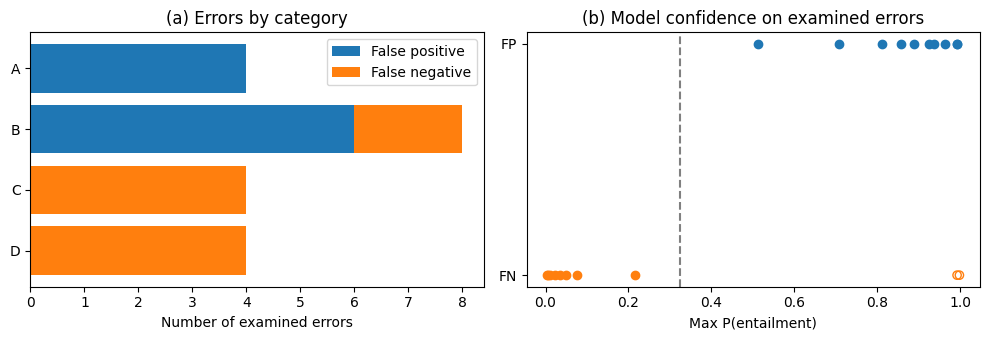

In [45]:
# Part 3: categories of the 20 examined errors, statistics and chart
import json, collections
import matplotlib.pyplot as plt

errors = json.load(open("entailment_errors.json"))

categories = {  # fact -> category (A/B/C/D), from manual examination
    "Cleveland is in Ohio.": "B",
    "She transitioned to acting.": "B",
    "Itakura has represented Japan at the Under-19-level.": "A",
    "Trivisonno worked at WMMS.": "A",
    "Trivisonno worked at WKNR.": "A",
    "She has worked with a number of organizations.": "B",
    "He has worked as a researcher at various organizations.": "B",
    "Mayo Clinic is an organization.": "B",
    "He has worked at Mayo Clinic.": "A",
    "Jidenna's music is a fusion of hip-hop.": "B",
    "Gerhard Fischer is best known for inventing a metal detector.": "D",
    "Gerhard Fischer invented the first handheld, battery-operated metal detector.": "D",
    "Jean Daullé was known for his portraits.": "B",
    "The Taker trilogy is a novel by Katsu.": "C",
    "The Hunger is a novel by Katsu.": "C",
    "He served for many years as a pastor.": "C",
    "Hibo Wardere is based in the United Kingdom.": "D",
    "With CSKA, he won domestic titles.": "C",
    "Florencia Bertotti is an Argentinian.": "D",
    '"New Heart." is popular.': "B",
}

examined = [e for e in errors if e["fact"] in categories]
assert len(examined) == 20

# Aggregate statistics
counts = collections.Counter((categories[e["fact"]], e["type"]) for e in examined)
for cat in "ABCD":
    fp, fn = counts[(cat, "FP")], counts[(cat, "FN")]
    print(f"{cat}: FP={fp} FN={fn} total={fp + fn}")

# P(E) per error - for pruned facts use the cached would-have value
def p_e(e):
    return e["probs_E_N_C"][0] if e["pruned"] else e["score"]

fps = [p_e(e) for e in examined if e["type"] == "FP"]
fns_model = [e["score"] for e in examined if e["type"] == "FN" and not e["pruned"]]
print("FPs with P(E) > 0.70:", sum(p > 0.70 for p in fps), "of", len(fps))
print("FNs reaching the model with P(E) < 0.1:", sum(p < 0.1 for p in fns_model), "of", len(fns_model))

# Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
cats = ["A", "B", "C", "D"]
fp_counts = [counts[(c, "FP")] for c in cats]
fn_counts = [counts[(c, "FN")] for c in cats]
ax1.barh(cats, fp_counts, label="False positive")
ax1.barh(cats, fn_counts, left=fp_counts, label="False negative")
ax1.invert_yaxis(); ax1.set_xlabel("Number of examined errors"); ax1.legend()
ax1.set_title("(a) Errors by category")

for e in examined:
    y = 1 if e["type"] == "FP" else 0
    hollow = e["pruned"]
    ax2.scatter(p_e(e), y, facecolors="none" if hollow else ("C0" if y else "C1"),
                edgecolors="C0" if y else "C1")
ax2.axvline(0.325, linestyle="--", color="grey")
ax2.set_yticks([0, 1]); ax2.set_yticklabels(["FN", "FP"]); ax2.set_xlabel("Max P(entailment)")
ax2.set_title("(b) Model confidence on examined errors")
plt.tight_layout(); import os; os.makedirs("figures", exist_ok=True)
plt.savefig("error_statistics.png", dpi=200); plt.show()

In [40]:
# Part 3, Example 2: why "Florencia Bertotti is an Argentinian." was pruned
import re
fact = "Florencia Bertotti is an Argentinian."
e = next(e for e in errors if e["fact"] == fact)
passages = next(ex.passages for ex in examples if ex.fact == fact)

# Fact side
fact_terms = set(overlap_scorer.tokenize(fact))
title_terms = set(overlap_scorer.tokenize(re.sub(r"\(.*?\)", " ", passages[0]["title"])))
print("Fact stems:", fact_terms)
print("After name removal:", fact_terms - title_terms)

# Evidence side
sentences = [s for p in passages for s in overlap_scorer.split_into_sentences(p["text"])]
evidence = next(s for s in sentences if "Argentine" in s)
print("Evidence sentence:", evidence[:150])
print("Evidence stems:", overlap_scorer.tokenize(evidence))
print("Any evidence sentence contains 'argentinian':",
      any("argentinian" in overlap_scorer.tokenize(s) for s in sentences))

# Result
print("Overlap score:", overlap_scorer.score(fact, passages), "< 0.1 -> pruned")
print("Cached P(E) if not pruned:", e["probs_E_N_C"][0])

Fact stems: {'florencia', 'argentinian', 'bertotti'}
After name removal: {'argentinian'}
Evidence sentence: Florencia Bertotti María Florencia Bertotti (born 15 March 1983), better known as Florencia Bertotti is an Argentine actress, singer, songwriter and b
Evidence stems: ['florencia', 'bertotti', 'mar', 'florencia', 'bertotti', 'born', '15', 'march', '1983', 'better', 'known', 'florencia', 'bertotti', 'argentin', 'actress', 'singer', 'songwrit', 'businesswoman']
Any evidence sentence contains 'argentinian': False
Overlap score: 0.0 < 0.1 -> pruned
Cached P(E) if not pruned: 0.993


In [41]:
# Evidence for the Reason column and the set-aside cases
keywords = {
    "Itakura has represented Japan at the Under-19-level.": "U-20|Under",
    "Trivisonno worked at WMMS.": "WMMS",
    "He has worked at Mayo Clinic.": "Mayo",
    "Gerhard Fischer is best known for inventing a metal detector.": "Fisher",
    "He served for many years as a pastor.": "pastor",
    "With CSKA, he won domestic titles.": "Honours|Premier League",
    "Hibo Wardere is based in the United Kingdom.": "London",
    '"New Heart." is popular.': "New Heart",
    "He served as a sniper.": "sniper",
    "She was born on July 18, 1987.": "born",
    "They divorced in 1964.": "divorc|1964",
}
for fact, pattern in keywords.items():
    e = next(e for e in errors if e["fact"] == fact)
    passages = next(ex.passages for ex in examples if ex.fact == fact)
    hits = [m.group(0) for p in passages
            for m in re.finditer(rf".{{0,80}}({pattern}).{{0,80}}", p["text"])]
    print(f"\n{fact}\n  best premise: {e['best_premise'][:120]}")
    print("  passage matches:", hits[:2] if hits else "NONE")


Itakura has represented Japan at the Under-19-level.
  best premise: In May 2017, Itakura was called up to the Japan U-20 national team for the 2017 U-20 World Cup. At this tournament, he p
  passage matches: ['ee.</s><s>International career. In May 2017, Itakura was called up to the Japan U-20 national team for the 2017 U-20 World Cup. At this tournament, he played 2 matc']

Trivisonno worked at WMMS.
  best premise: He was a frequent caller on the "Sportsline" radio show on WTAM AM 1100 (during this period the station was operating un
  passage matches: NONE

He has worked at Mayo Clinic.
  best premise: in Biomedical Engineering from the Mayo Clinic and B.S. degrees in Mathematics and Electrical Engineering from Brigham Y
  passage matches: ['rly life and education. Oliphant has a Ph.D. in Biomedical Engineering from the Mayo Clinic and B.S. and M.S. degrees in Mathematics and Electrical Engineering from']

Gerhard Fischer is best known for inventing a metal detector.
  best premis

In [42]:
# Count model calls of the final EntailmentFactChecker using cached probabilities
from factcheck import EntailmentFactChecker

lut = {(examples[p["fact_idx"]].fact, p["premise_window"]): pr
       for p, pr in zip(pairs, cache["probs_window"])}

class CountingModel:
    calls = 0
    def check_entailment_batch(self, premises, hypotheses):
        CountingModel.calls += len(premises)
        return np.stack([lut[(h, p)] for p, h in zip(premises, hypotheses)])

for tau in [0.0, 0.1]:
    CountingModel.calls = 0
    fc = EntailmentFactChecker(CountingModel(), prune_threshold=tau)
    fc.overlap_checker = overlap_scorer          # use the global-IDF scorer
    for ex in examples:
        fc.predict(ex.fact, ex.passages)
    print(f"tau={tau}: {CountingModel.calls} model calls, "
          f"{1 - CountingModel.calls / len(pairs):.1%} skipped")

tau=0.0: 4186 model calls, 22.7% skipped
tau=0.1: 3394 model calls, 37.3% skipped


In [43]:
# "Contradiction is near zero for the best premise" (Part 2 strategies)
best = {}
for k, p in enumerate(pairs):
    i = p["fact_idx"]
    if i not in best or cache["probs_window"][k][0] > cache["probs_window"][best[i]][0]:
        best[i] = k
pc = np.array([cache["probs_window"][k][2] for k in best.values()])
print(f"P(C) of best premise: median {np.median(pc):.3f}, {np.mean(pc < 0.05):.0%} below 0.05")

P(C) of best premise: median 0.003, 81% below 0.05
